<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/07_resultado_final_consolidado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07. Síntese Executiva e Resultados Finais
## Análise de Financiamento Municipal e Desenvolvimento no Rio Grande do Norte (2020 a 2023)

**Projeto da Unidade 2 - Ciência de Dados (UFRN / IMD)**  
**Autores:** Brenda Gomes, Fernanda Nascimento, Gabriel Borges e Renata Nascimento  
**Orientação:** Prof. Daniel Sabino  

---

### Pergunta Norteadora da Avaliação:
> *"Existe dependência do fundo de participação para ofertar serviços de qualidade para a população?"*

### Objetivo deste Notebook:
Este documento consolida o resultado final de toda a pesquisa sobre financiamento público municipal no RN, oferecendo uma visão integrada em dois níveis complementares:
1. **Nível Macro e Agregado**: O diagnóstico estrutural de dependência fiscal do FPM, a rigidez orçamentária e a dispersão geral nos 167 municípios potiguares.
2. **Nível Desagregado (Cidade a Cidade / Par a Par)**: O exame individualizado de cada um dos **7 pares de cidades gêmeas** (14 municípios ao todo), permitindo comparar minuciosamente as receitas, despesas por área e indicadores sociais reais de cada cidade lado a lado.


## 1. Setup, Bibliotecas e Funções Auxiliares

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
pd.set_option('display.max_columns', 35)
pd.set_option('display.max_colwidth', 80)

# Paleta de cores oficial do projeto
LARANJA = '#eb6834'      # Cidades em destaque (super-arrecadadoras)
AZUL = '#2a78d6'         # Cidades gêmeas (controle / municípios normais)
VERDE = '#1baf7a'        # Vitórias / desempenho favorável
VERMELHO = '#d0453c'     # Alertas / carências sociais
ROXO = '#7d55c7'         # FPM / transferências federais
AMARELO = '#eda100'      # Receita própria
CINZA = '#a3a29b'        # Geral / neutro
CINZA_CLARO = '#e5e4de'  # Grades
TEXTO = '#1a1a1a'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'figure.dpi': 120,
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'legend.frameon': True,
    'figure.autolayout': False
})

def formatar_reais(x, _=None):
    sinal = '−' if x < 0 else ''
    x = abs(x)
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if x >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.1f}'.replace('.', ',')
            return f'{sinal}R$ {texto}{sufixo}'
    return f'{sinal}R$ {x:.0f}'

def carregar_dados(caminho):
    tentativas = [
        caminho,
        os.path.join('..', caminho),
        os.path.join('..', '..', caminho),
        os.path.join('resultado_final', caminho)
    ]
    for p in tentativas:
        if os.path.exists(p):
            return pd.read_csv(p)
    url = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/' + caminho
    return pd.read_csv(url)

print('Ambiente configurado com sucesso.')


Ambiente configurado com sucesso.


## 2. Carregamento e Preparação das Bases Fiscais e Sociais

In [2]:
# Carga das bases oficiais tratadas
pares = carregar_dados('resultado_final/saida/05_pares_gemeos.csv')
uni = carregar_dados('resultado_final/saida/04_base_unificada_2020_2023.csv')
base01 = carregar_dados('resultado_final/saida/01_base_municipios_2020_2023.csv')
dca = carregar_dados('dados/siconfi/dca_pares_2020_2023.csv')

FATOR_IPCA = base01.drop_duplicates('ano').set_index('ano')['fator_ipca']
POP = uni.set_index('cod_ibge')['populacao']
NOME = uni.set_index('cod_ibge')['municipio']

PARES = list(zip(pares['destaque'], pares['gemea']))
DESTAQUES = pares['destaque'].tolist()
GEMEAS = pares['gemea'].tolist()
CIDADES = DESTAQUES + GEMEAS
ROTULO_PAR = {d: f'{d} × {g}' + (' (fronteira)' if f else '')
              for d, g, f in zip(pares['destaque'], pares['gemea'], pares['fronteira'])}

# Ajustes no SICONFI
dca['municipio'] = dca['cod_ibge'].map(NOME)
dca['valor_real'] = dca['valor'] * dca['exercicio'].map(FATOR_IPCA)
dca['valor_pc'] = dca['valor_real'] / dca['cod_ibge'].map(POP)

# Carga das bases sociais
censo_ind = carregar_dados('dados/ibge/censo2010_2022_indicadores_rn.csv')
censo22 = carregar_dados('dados/ibge/censo2022_renda_rn.csv')[['cod_ibge', 'pct_ate_meio_sm_censo']]
ideb = carregar_dados('dados/inep/ideb_rede_municipal_rn.csv')[['cod_ibge', 'ai_2017', 'ai_2019', 'ai_2021', 'ai_2023']]
saude = carregar_dados('dados/saude/mortalidade_infantil_rn.csv')
saude['valor'] = pd.to_numeric(saude['valor'].astype(str).replace('-', '0'), errors='coerce')
saude_piv = (saude[saude['indicador'] != 'taxa']
             .pivot_table(index=['cod_ibge6', 'ano'], columns='indicador', values='valor').reset_index())

def taxa_mortalidade(inicio, fim):
    s = saude_piv[saude_piv['ano'].between(inicio, fim)].groupby('cod_ibge6')[['obitos_menor_1_ano', 'nascidos_vivos']].sum()
    return s['obitos_menor_1_ano'] / s['nascidos_vivos'] * 1000

cad = base01.pivot_table(index='cod_ibge', columns='ano', values='pct_baixa_renda')

# Base unificada com indicadores
ind = (uni[['cod_ibge', 'municipio', 'populacao', 'total_pc_ano']]
       .merge(censo_ind, on='cod_ibge')
       .merge(censo22, on='cod_ibge')
       .merge(ideb, on='cod_ibge', how='left'))

ind['cod_ibge6'] = ind['cod_ibge'] // 10
ind['mort_antes'] = ind['cod_ibge6'].map(taxa_mortalidade(2016, 2019))
ind['mort_2020_2023'] = ind['cod_ibge6'].map(taxa_mortalidade(2020, 2023))
ind['cad_media'] = ind['cod_ibge'].map(cad.mean(axis=1))
ind['cad_2020'] = ind['cod_ibge'].map(cad[2020])
ind['cad_2023'] = ind['cod_ibge'].map(cad[2023])

ind['mud_pobreza'] = ind['pobre10'] - ind['pct_ate_meio_sm_censo']
ind['mud_cad'] = ind['cad_2020'] - ind['cad_2023']
ind['mud_ideb'] = ind['ai_2023'] - ind['ai_2019']
ind['mud_mort'] = ind['mort_antes'] - ind['mort_2020_2023']

print(f'Bases integradas: {len(ind)} municípios potiguares, com 14 cidades pareadas em 7 pares.')


Bases integradas: 167 municípios potiguares, com 14 cidades pareadas em 7 pares.


## 3. De Onde Vem o Dinheiro? Estrutura de Receita e Dependência Fiscal

Respondendo à primeira parte da pergunta norteadora da disciplina:
> *"Existe dependência do fundo de participação para ofertar serviços de qualidade para a população?"*

Avaliamos a composição da receita corrente das cidades no SICONFI:
* **FPM**: Fundo de Participação dos Municípios.
* **Transferências do Estado**: Devoluções de ICMS, IPVA e royalties estaduais.
* **Outras Transferências da União**: Recursos vinculados ao SUS, FNDE e outros fundos.
* **FUNDEB**: Fundo de Manutenção da Educação Básica.
* **Receita Própria**: Tributos municipais arrecadados localmente (IPTU, ISS, taxas).


In [3]:
# Contas contábeis de receita no SICONFI (DCA Anexo I-C)
rec = dca[(dca['anexo'] == 'DCA-Anexo I-C') & (dca['coluna'] == 'Receitas Brutas Realizadas')]
r = rec.pivot_table(index=['cod_ibge', 'exercicio'], columns='cod_conta', values='valor_real', aggfunc='sum').fillna(0)

fpm = np.where(r.index.get_level_values('exercicio') >= 2022, r.get('RO1.7.1.1.51.0.0', 0), r.get('RO1.7.1.8.01.2.0', 0))
icms = np.where(r.index.get_level_values('exercicio') >= 2022, r.get('RO1.7.2.1.50.0.0', 0), r.get('RO1.7.2.8.01.1.0', 0))
ipva = np.where(r.index.get_level_values('exercicio') >= 2022, r.get('RO1.7.2.1.51.0.0', 0), r.get('RO1.7.2.8.01.2.0', 0))

rec_tipo = pd.DataFrame({
    'Receita corrente total': r.get('RO1.0.0.0.00.0.0', 0),
    'Receita tributaria propria': r.get('RO1.1.0.0.00.0.0', 0),
    'Transferencias totais': r.get('RO1.7.0.0.00.0.0', 0),
    'FPM': fpm,
    'Transferencias da Uniao (total)': r.get('RO1.7.1.0.00.0.0', 0),
    'ICMS': icms,
    'IPVA': ipva,
    'Transferencias do Estado (total)': r.get('RO1.7.2.0.00.0.0', 0),
    'FUNDEB': r.get('RO1.7.5.0.00.0.0', 0),
}, index=r.index)
rec_tipo['municipio'] = rec_tipo.index.get_level_values('cod_ibge').map(NOME)
rec_med = rec_tipo.groupby('municipio').mean()

pop_mun = uni.set_index('municipio')['populacao']
rc_pc = rec_med['Receita corrente total'] / pop_mun
fpm_pc = rec_med['FPM'] / pop_mun
estado_pc = rec_med['Transferencias do Estado (total)'] / pop_mun
propria_pc = rec_med['Receita tributaria propria'] / pop_mun

# Composição percentual (fatias da receita corrente)
rc = rec_med['Receita corrente total']
fatias = pd.DataFrame({
    'Receita própria': rec_med['Receita tributaria propria'] / rc * 100,
    'FPM': rec_med['FPM'] / rc * 100,
    'Outras transferências da União': (rec_med['Transferencias da Uniao (total)'] - rec_med['FPM']) / rc * 100,
    'Transferências do Estado': rec_med['Transferencias do Estado (total)'] / rc * 100,
    'FUNDEB': rec_med['FUNDEB'] / rc * 100,
})

media_destaques = fatias.loc[DESTAQUES].mean()
media_gemeas = fatias.loc[GEMEAS].mean()

resumo_dep = pd.DataFrame({
    'Cidades Gêmeas (Municípios Típicos)': media_gemeas,
    'Cidades em Destaque (Super-arrecadadoras)': media_destaques
}).round(1)
resumo_dep['Diferença (pontos percentuais)'] = (resumo_dep['Cidades em Destaque (Super-arrecadadoras)'] - resumo_dep['Cidades Gêmeas (Municípios Típicos)']).round(1)
display(resumo_dep)


,Cidades Gêmeas (Municípios Típicos),Cidades em Destaque (Super-arrecadadoras),Diferença (pontos percentuais)
Receita própria,5.7,10.1,4.4
FPM,46.9,27.0,-19.9
Outras transferências da União,19.9,11.8,-8.1
Transferências do Estado,9.9,38.5,28.6
FUNDEB,14.5,10.7,-3.8


### Gráfico 1: A Falsa Independência Fiscal das Cidades Outliers

O gráfico a seguir ilustra a distribuição percentual média da receita corrente entre os dois grupos. Note como o FPM é o pilar absoluto das cidades gêmeas, enquanto as cidades destacadas continuam dependentes de transferências externas (89%), mas trocam o FPM por repasses estaduais e royalties.

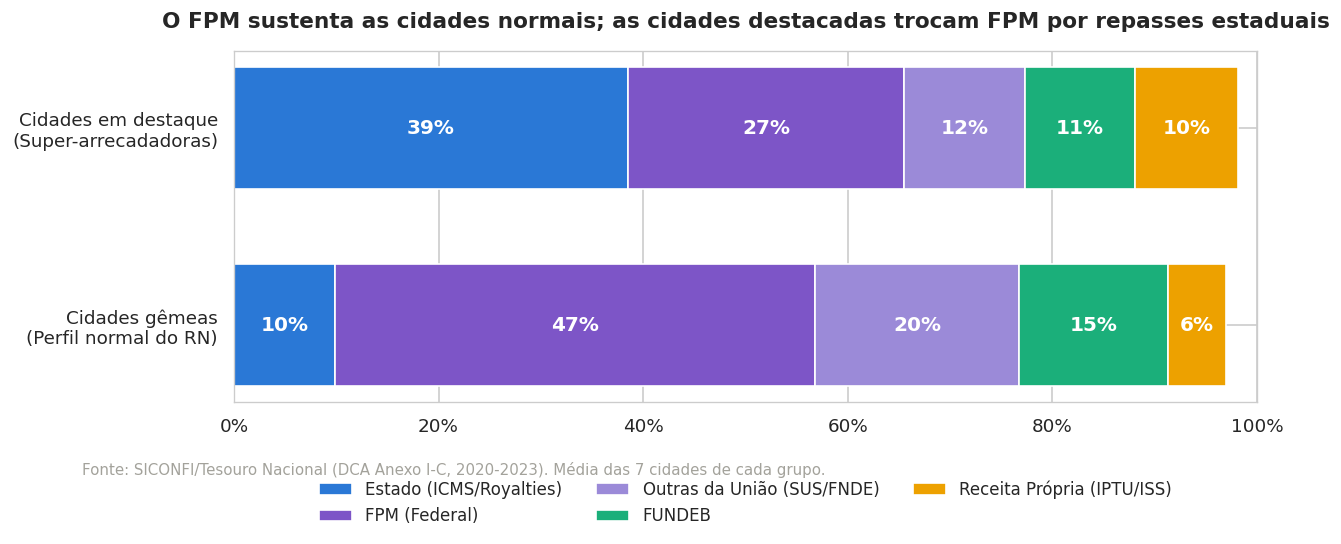

In [4]:
# Gráfico 1: Composição da Receita Corrente (Destaque vs Gêmea)
partes = [
    ('Transferências do Estado', 'Estado (ICMS/Royalties)', AZUL),
    ('FPM', 'FPM (Federal)', ROXO),
    ('Outras transferências da União', 'Outras da União (SUS/FNDE)', '#9b8ad8'),
    ('FUNDEB', 'FUNDEB', VERDE),
    ('Receita própria', 'Receita Própria (IPTU/ISS)', AMARELO)
]

fig, ax = plt.subplots(figsize=(11, 3.8))
for y_pos, (label, serie) in enumerate([('Cidades gêmeas\n(Perfil normal do RN)', media_gemeas),
                                       ('Cidades em destaque\n(Super-arrecadadoras)', media_destaques)]):
    esq = 0
    for col, rot, cor in partes:
        v = serie[col]
        ax.barh(y_pos, v, left=esq, color=cor, edgecolor='white', height=0.62, label=rot if y_pos == 0 else None)
        if v >= 5:
            ax.text(esq + v / 2, y_pos, f'{v:.0f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=12)
        esq += v

ax.set_yticks([0, 1])
ax.set_yticklabels(['Cidades gêmeas\n(Perfil normal do RN)', 'Cidades em destaque\n(Super-arrecadadoras)'], fontsize=11)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title('O FPM sustenta as cidades normais; as cidades destacadas trocam FPM por repasses estaduais', pad=14, fontsize=13)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False, fontsize=10)
fig.text(0.01, -0.05, 'Fonte: SICONFI/Tesouro Nacional (DCA Anexo I-C, 2020-2023). Média das 7 cidades de cada grupo.', fontsize=9, color=CINZA)
plt.show()


## 4. Para Onde Vai o Dinheiro Excedente?

Avaliamos as despesas orçamentárias liquidadas por função de governo no SICONFI (Anexo I-E):
* Calculamos a despesa per capita em cada área pública (Saúde, Educação, Administração, Obras, etc.).
* Calculamos a diferença líquida entre a cidade em destaque e sua gêmea de controle.
* Decompomos: **A cada R$ 100 adicionais gastos por habitante, quantos reais vão para cada área?**


In [5]:
# Extração das despesas liquidadas por função (DCA Anexo I-E)
desp_area = dca[(dca['anexo'] == 'DCA-Anexo I-E') & (dca['coluna'] == 'Despesas Liquidadas')].copy()

desp_area['intra'] = (desp_area['conta'].eq('Despesas Intraorçamentárias')
                      .groupby([desp_area['cod_ibge'], desp_area['exercicio']]).cumsum() > 0)
desp_area = desp_area[~desp_area['intra']]
funcoes = desp_area[desp_area['conta'].str.match(r'^\d{2} - ')].copy()
funcoes['codigo'] = funcoes['conta'].str[:2]

AREAS = {
    '12': 'Educação',
    '10': 'Saúde',
    '15': 'Urbanismo (obras e serviços urbanos)',
    '04': 'Administração e Câmara',
    '01': 'Administração e Câmara',
    '08': 'Assistência social',
    '17': 'Saneamento e meio ambiente',
    '18': 'Saneamento e meio ambiente',
    '26': 'Transporte',
    '13': 'Cultura, esporte e lazer',
    '27': 'Cultura, esporte e lazer',
    '23': 'Cultura, esporte e lazer',
    '20': 'Agricultura',
    '09': 'Previdência',
    '28': 'Encargos e dívidas'
}
funcoes['area'] = funcoes['codigo'].map(AREAS).fillna('Outras áreas')

area_pc = (funcoes.groupby(['municipio', 'area'])['valor_real'].sum().unstack(fill_value=0)
           .div(uni.set_index('municipio')['populacao'], axis=0).dropna() / 4)

def decompor_diferenca(tabela):
    linhas = []
    for d, g in PARES:
        dif = tabela.loc[d] - tabela.loc[g]
        total = dif.sum()
        s = pd.Series(dif / total * 100, name=d)
        s['__total'] = total
        linhas.append(s)
    return pd.DataFrame(linhas)

dec_area = decompor_diferenca(area_pc)
shares = dec_area.drop(columns='__total')
mediana_areas = shares.median().sort_values(ascending=False)

print('Decomposição mediana do gasto excedente (a cada R$ 100 adicionais):')
for area, val in mediana_areas.items():
    print(f' - {area:35s}: R$ {val:5.1f}')


Decomposição mediana do gasto excedente (a cada R$ 100 adicionais):
 - Administração e Câmara             : R$  40.2
 - Saúde                              : R$  24.0
 - Educação                           : R$  19.7
 - Assistência social                 : R$   8.2
 - Cultura, esporte e lazer           : R$   4.2
 - Encargos e dívidas                 : R$   2.6
 - Agricultura                        : R$   2.4
 - Urbanismo (obras e serviços urbanos): R$   1.7
 - Transporte                         : R$   1.3
 - Outras áreas                       : R$   0.7
 - Saneamento e meio ambiente         : R$   0.4


### Gráfico 2: A Cada R\$ 100 a Mais, R\$ 40 Vão Para a Máquina Pública

O gráfico horizontal abaixo revela a grande conclusão sobre a alocação dos recursos:
* A mediana dos 7 pares mostra que **R\$ 39,80 (arredondado para R\$ 40)** de cada R\$ 100 adicionais vão para **Administração Direta, Gabinetes e Câmaras Municipais**.
* A **Saúde** recebe R\$ 24 e a **Educação** recebe R\$ 20.
* Áreas estruturantes como **Urbanismo, Saneamento, Habitação e Meio Ambiente** recebem apenas centavos ou valores residuais.


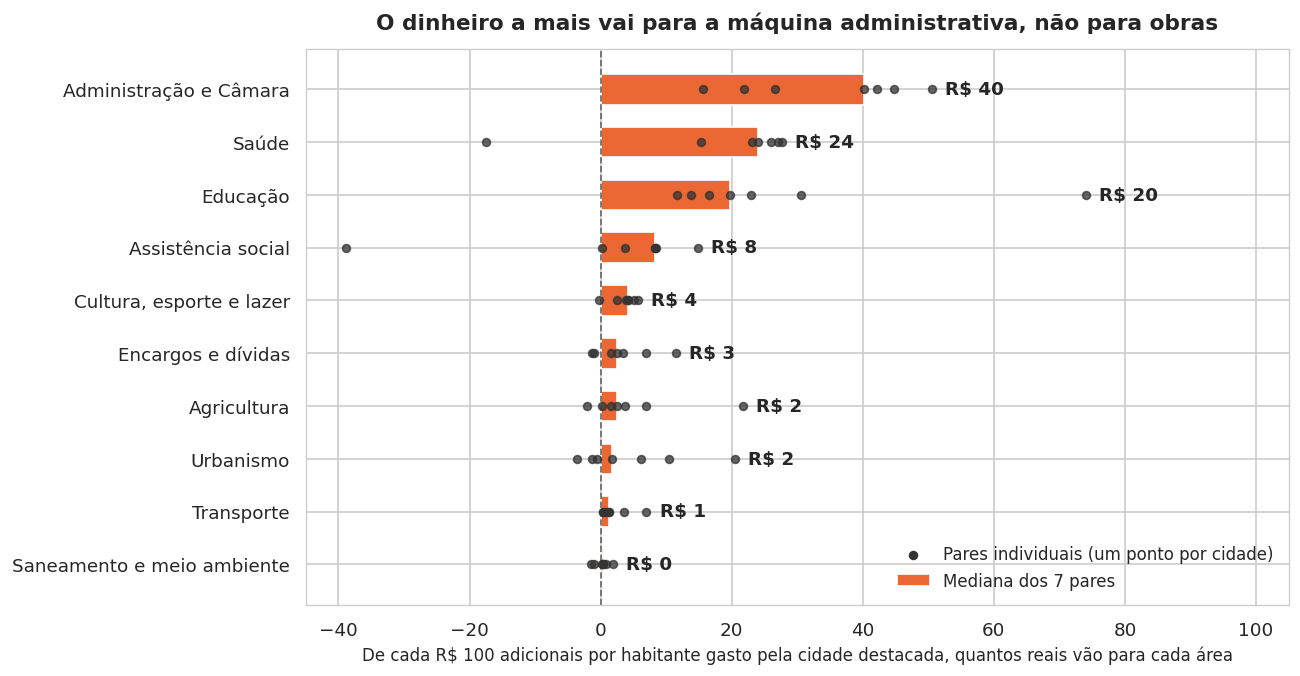

In [6]:
# Gráfico 2: O dinheiro a mais vai para a máquina administrativa
ordem_plot = [
    'Administração e Câmara', 'Saúde', 'Educação', 'Assistência social',
    'Cultura, esporte e lazer', 'Encargos e dívidas', 'Agricultura',
    'Urbanismo (obras e serviços urbanos)', 'Transporte', 'Saneamento e meio ambiente'
]

fig, ax = plt.subplots(figsize=(11, 5.8))
y_coords = np.arange(len(ordem_plot))[::-1]

ax.barh(y_coords, [mediana_areas.get(o, 0) for o in ordem_plot], color=LARANJA, height=0.58, label='Mediana dos 7 pares')

for yi, o in zip(y_coords, ordem_plot):
    vals = shares[o]
    ax.scatter(vals, [yi] * len(vals), color='#333333', s=22, zorder=3, alpha=0.75)
    med_val = mediana_areas.get(o, 0)
    max_val = max(vals.max(), med_val)
    ax.text(max_val + 2, yi, f'R$ {med_val:.0f}', va='center', fontweight='bold', fontsize=11)

ax.scatter([], [], color='#333333', s=22, label='Pares individuais (um ponto por cidade)')
ax.set_yticks(y_coords)
ax.set_yticklabels([o.replace(' (obras e serviços urbanos)', '') for o in ordem_plot], fontsize=11)
ax.axvline(0, color='#666666', lw=1, linestyle='--')
ax.set_xlim(-45, 105)
ax.set_xlabel('De cada R$ 100 adicionais por habitante gasto pela cidade destacada, quantos reais vão para cada área', fontsize=10)
ax.set_title('O dinheiro a mais vai para a máquina administrativa, não para obras', pad=12, fontsize=13)
ax.legend(loc='lower right', frameon=False, fontsize=10)
plt.tight_layout()
plt.show()


## 5. Comparativo Individual Cidade a Cidade (Par a Par)

Para além das médias e medianas agrupadas, examinamos aqui a **realidade individual de cada um dos 7 pares de cidades gêmeas**.
Cada par foi selecionado com base em:
* População rigorosamente equivalente (Censo Demográfico 2022).
* Mesma mesorregião geográfica e características de relevo e bioma.
* Diferença brutal de repasses: enquanto a cidade em destaque recebe vultosos royalties e emendas, sua gêmea de controle sobrevive apenas com o orçamento ordinário.

Abaixo, apresentamos a **tabela comparativa detalhada de todas as 14 cidades individuais**, seguida de gráficos específicos cidade a cidade para receitas, despesas e indicadores sociais.


In [7]:
# Construção da tabela detalhada cidade a cidade para as 14 cidades dos 7 pares
desp_tipo = dca[(dca['anexo'] == 'DCA-Anexo I-D') & (dca['coluna'] == 'Despesas Liquidadas')]
t = desp_tipo.pivot_table(index='municipio', columns='cod_conta', values='valor_real', aggfunc='sum').fillna(0)
tipo_pc = pd.DataFrame({
    'Custeio_Pessoal': t['DO3.1.00.00.00.00'] + t['DO3.3.00.00.00.00'] + t.get('DO3.2.00.00.00.00', 0),
    'Investimento': t.get('DO4.4.00.00.00.00', 0)
}).div(uni.set_index('municipio')['populacao'], axis=0).dropna() / 4
pct_inv = tipo_pc['Investimento'] / tipo_pc.sum(axis=1) * 100

ind_i = ind.set_index('municipio')

linhas_cidades = []
for idx, (d, g) in enumerate(PARES):
    for papel, mun in [('Destaque', d), ('Gêmea', g)]:
        linhas_cidades.append({
            'Par': idx + 1,
            'Papel': papel,
            'Município': mun,
            'População': int(pop_mun[mun]),
            'Receita Total (R$/hab)': rc_pc[mun],
            'FPM (R$/hab)': fpm_pc[mun],
            'Estado/Royalties (R$/hab)': estado_pc[mun],
            'Adm/Câmara (R$/hab)': area_pc.loc[mun, 'Administração e Câmara'],
            'Saúde (R$/hab)': area_pc.loc[mun, 'Saúde'],
            'Educação (R$/hab)': area_pc.loc[mun, 'Educação'],
            'Investimento (%)': pct_inv[mun],
            'Água da Rede (%)': ind_i.loc[mun, 'agua22'],
            'Esgoto Adequado (%)': ind_i.loc[mun, 'esg22'],
            'Lixo Coletado (%)': ind_i.loc[mun, 'lixo22'],
            'Pobreza CadÚnico (%)': ind_i.loc[mun, 'cad_media'],
            'IDEB 2023': ind_i.loc[mun, 'ai_2023'] if not pd.isna(ind_i.loc[mun, 'ai_2023']) else np.nan,
        })

df_cidades = pd.DataFrame(linhas_cidades)

# Formatação executiva da tabela
df_formatado = df_cidades.copy()
df_formatado['População'] = df_formatado['População'].apply(lambda x: f'{x:,.0f}'.replace(',', '.'))
df_formatado['Receita Total (R$/hab)'] = df_formatado['Receita Total (R$/hab)'].apply(lambda x: f'R$ {x:,.0f}'.replace(',', '.'))
df_formatado['FPM (R$/hab)'] = df_formatado['FPM (R$/hab)'].apply(lambda x: f'R$ {x:,.0f}'.replace(',', '.'))
df_formatado['Estado/Royalties (R$/hab)'] = df_formatado['Estado/Royalties (R$/hab)'].apply(lambda x: f'R$ {x:,.0f}'.replace(',', '.'))
df_formatado['Adm/Câmara (R$/hab)'] = df_formatado['Adm/Câmara (R$/hab)'].apply(lambda x: f'R$ {x:,.0f}'.replace(',', '.'))
df_formatado['Saúde (R$/hab)'] = df_formatado['Saúde (R$/hab)'].apply(lambda x: f'R$ {x:,.0f}'.replace(',', '.'))
df_formatado['Educação (R$/hab)'] = df_formatado['Educação (R$/hab)'].apply(lambda x: f'R$ {x:,.0f}'.replace(',', '.'))
df_formatado['Investimento (%)'] = df_formatado['Investimento (%)'].apply(lambda x: f'{x:.1f}%'.replace('.', ','))
df_formatado['Água da Rede (%)'] = df_formatado['Água da Rede (%)'].apply(lambda x: f'{x:.1f}%'.replace('.', ','))
df_formatado['Esgoto Adequado (%)'] = df_formatado['Esgoto Adequado (%)'].apply(lambda x: f'{x:.1f}%'.replace('.', ','))
df_formatado['Lixo Coletado (%)'] = df_formatado['Lixo Coletado (%)'].apply(lambda x: f'{x:.1f}%'.replace('.', ','))
df_formatado['Pobreza CadÚnico (%)'] = df_formatado['Pobreza CadÚnico (%)'].apply(lambda x: f'{x:.1f}%'.replace('.', ','))
df_formatado['IDEB 2023'] = df_formatado['IDEB 2023'].apply(lambda x: f'{x:.1f}'.replace('.', ',') if not pd.isna(x) else 's/d')

display(df_formatado)


,Par,Papel,Município,População,Receita Total (R$/hab),FPM (R$/hab),Estado/Royalties (R$/hab),Adm/Câmara (R$/hab),Saúde (R$/hab),Educação (R$/hab),Investimento (%),Água da Rede (%),Esgoto Adequado (%),Lixo Coletado (%),Pobreza CadÚnico (%),IDEB 2023
0,1,Destaque,Guamaré,15.295,R$ 19.877,R$ 1.463,R$ 12.789,R$ 3.391,R$ 4.956,R$ 4.365,"1,7%","38,1%","58,5%","97,4%","66,9%","4,8"
1,1,Gêmea,Jardim de Piranhas,13.977,R$ 4.064,R$ 1.672,R$ 421,R$ 409,R$ 1.191,R$ 1.231,"6,0%","82,0%","36,6%","85,7%","59,6%","4,6"
2,2,Destaque,Galinhos,2.104,R$ 19.372,R$ 6.753,R$ 6.980,R$ 6.585,R$ 5.199,R$ 3.689,"2,7%","14,7%","17,1%","97,0%","72,3%","4,4"
3,2,Gêmea,Fernando Pedroza,2.938,R$ 8.760,R$ 4.695,R$ 944,R$ 1.418,R$ 2.431,R$ 2.006,"4,1%","86,7%","40,3%","90,7%","69,1%","3,8"
4,3,Destaque,Parazinho,4.801,R$ 11.173,R$ 2.854,R$ 4.846,R$ 2.783,R$ 2.345,R$ 2.411,"5,0%","77,1%","88,5%","79,3%","79,2%","5,0"
5,3,Gêmea,Bento Fernandes,4.807,R$ 5.983,R$ 2.851,R$ 575,R$ 1.074,R$ 1.242,R$ 1.913,"6,0%","86,2%","17,8%","76,0%","80,3%","3,6"
6,4,Destaque,São Bento do Norte,3.304,R$ 14.061,R$ 4.148,R$ 4.765,R$ 2.882,R$ 3.237,R$ 2.817,"7,0%","82,0%","2,6%","81,1%","81,0%","4,2"
7,4,Gêmea,São Fernando,3.492,R$ 7.207,R$ 3.925,R$ 904,R$ 1.134,R$ 1.716,R$ 1.912,"5,3%","85,4%","72,9%","77,1%","61,2%",s/d
8,5,Destaque,Pedra Grande,3.618,R$ 12.034,R$ 3.788,R$ 4.280,R$ 2.934,R$ 2.530,R$ 2.881,"6,5%","80,6%","63,4%","95,4%","81,4%",s/d
9,5,Gêmea,Senador Georgino Avelino,4.065,R$ 6.829,R$ 3.380,R$ 591,R$ 1.056,R$ 1.523,R$ 2.054,"9,3%","88,9%","9,1%","96,8%","69,9%","4,2"


### Gráfico 3: Comparativo de Receita por Habitante Cidade a Cidade

O gráfico abaixo mostra cada uma das 14 cidades individuais, agrupadas lado a lado em seus 7 pares.
Veja como o FPM (em roxo) é de valor quase idêntico entre a cidade em destaque e sua gêmea de controle. O abismo fiscal é produzido exclusivamente pelas **Transferências do Estado e Royalties (em azul escuro)**.

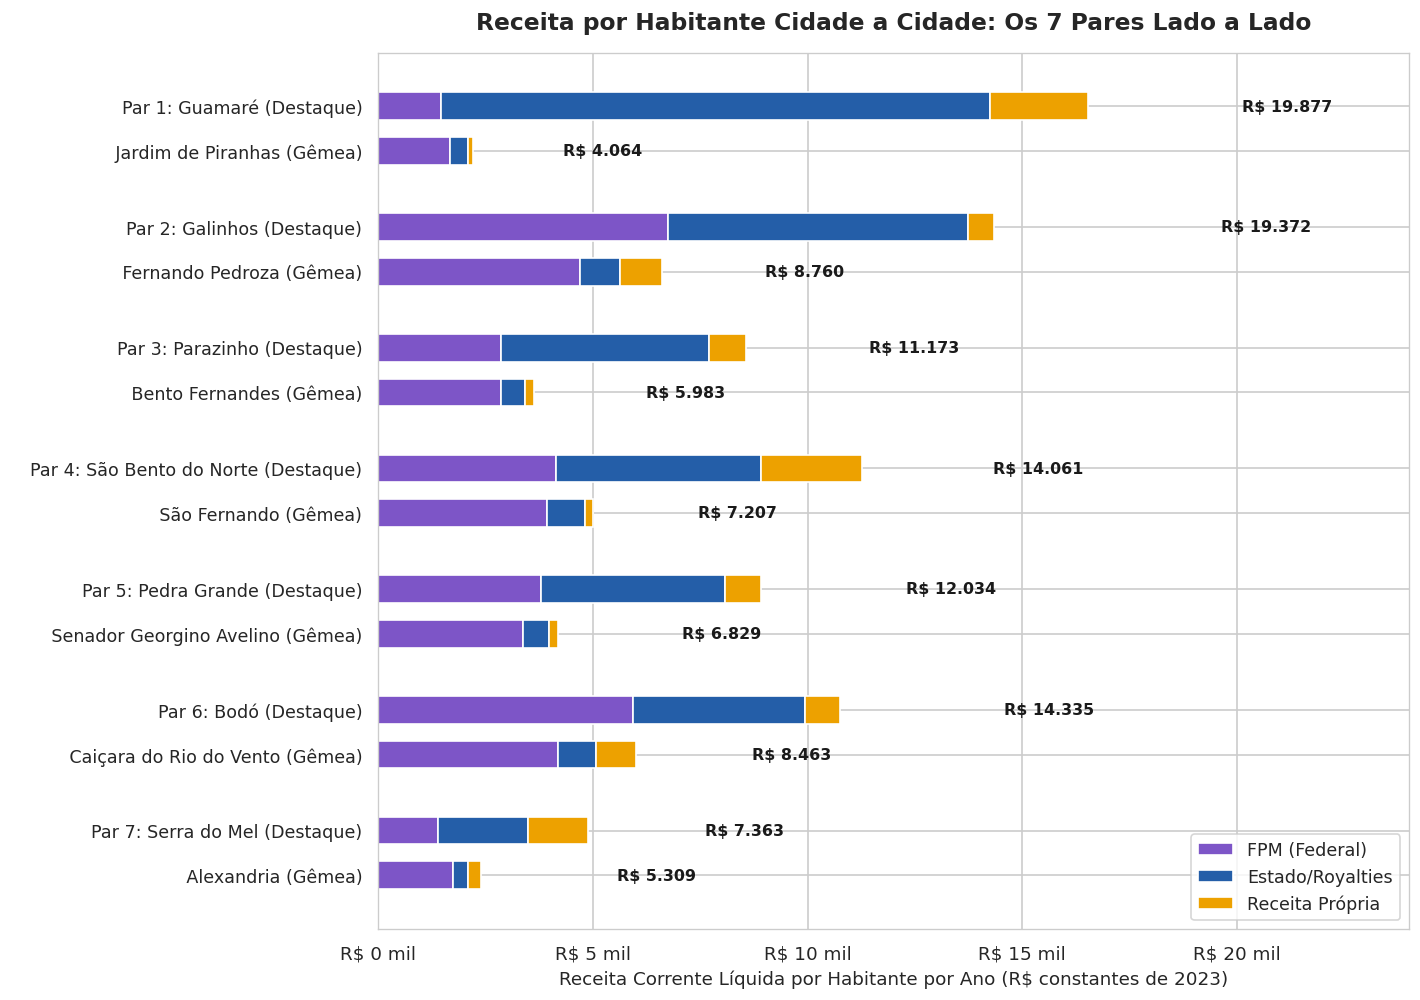

In [8]:
# Gráfico 3: Receita Corrente por Habitante Cidade a Cidade (Os 7 Pares)
fig, ax = plt.subplots(figsize=(12, 8.5))
y_ticks = []
y_labels = []
y_pos = 0

for idx, (d, g) in enumerate(PARES):
    for mun, cor in [(d, LARANJA), (g, AZUL)]:
        v_fpm = fpm_pc[mun]
        v_est = estado_pc[mun]
        v_prop = propria_pc[mun]
        v_tot = rc_pc[mun]

        # Barras empilhadas por fonte
        ax.barh(y_pos, v_fpm, color=ROXO, height=0.62, label='FPM (Federal)' if y_pos==0 else '')
        ax.barh(y_pos, v_est, left=v_fpm, color='#245ea8', height=0.62, label='Estado/Royalties' if y_pos==0 else '')
        ax.barh(y_pos, v_prop, left=v_fpm+v_est, color=AMARELO, height=0.62, label='Receita Própria' if y_pos==0 else '')

        # Rótulo de valor total ao lado da barra
        ax.text(v_tot + 250, y_pos, f'R$ {v_tot:,.0f}'.replace(',', '.'), va='center', fontsize=9.5, fontweight='bold', color=TEXTO)

        y_ticks.append(y_pos)
        papel = 'Destaque' if mun == d else 'Gêmea'
        rotulo_cidade = f'{mun} ({papel})'
        if mun == d:
            rotulo_cidade = f'Par {idx+1}: ' + rotulo_cidade
        else:
            rotulo_cidade = '       ' + rotulo_cidade
        y_labels.append(rotulo_cidade)
        y_pos += 1
    y_pos += 0.7  # Espaçamento entre os pares

ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels, fontsize=10.5)
ax.invert_yaxis()
ax.set_xlim(0, 24000)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x/1000:.0f} mil'))
ax.set_xlabel('Receita Corrente Líquida por Habitante por Ano (R$ constantes de 2023)', fontsize=11)
ax.set_title('Receita por Habitante Cidade a Cidade: 7 Pares Lado a Lado', pad=14, fontsize=14, fontweight='bold')
ax.legend(loc='lower right', frameon=True, fontsize=10.5)
plt.tight_layout()
plt.show()


### Gráfico 4: Onde Cada Cidade Gasta? Administração vs Saúde vs Educação

Neste painel com 3 gráficos lado a lado, examinamos os gastos por habitante nas 3 áreas mais importantes:

1. **Administração e Câmara**: Veja como Galinhos gasta **R\$ 6.585/hab** e Guamaré gasta **R\$ 3.391/hab** apenas com o funcionamento de gabinetes e burocracia política, enquanto suas gêmeas gastam entre R\$ 400 e R\$ 1.400.
2. **Saúde**: Os municípios com superávit de royalties gastam mais em termos brutos, mas esse valor é consumido em grande parte por contratos de terceirização e custeio.
3. **Educação**: O destaque individual é Serra do Mel (R\$ 1.858/hab) e Guamaré (R\$ 4.365/hab).


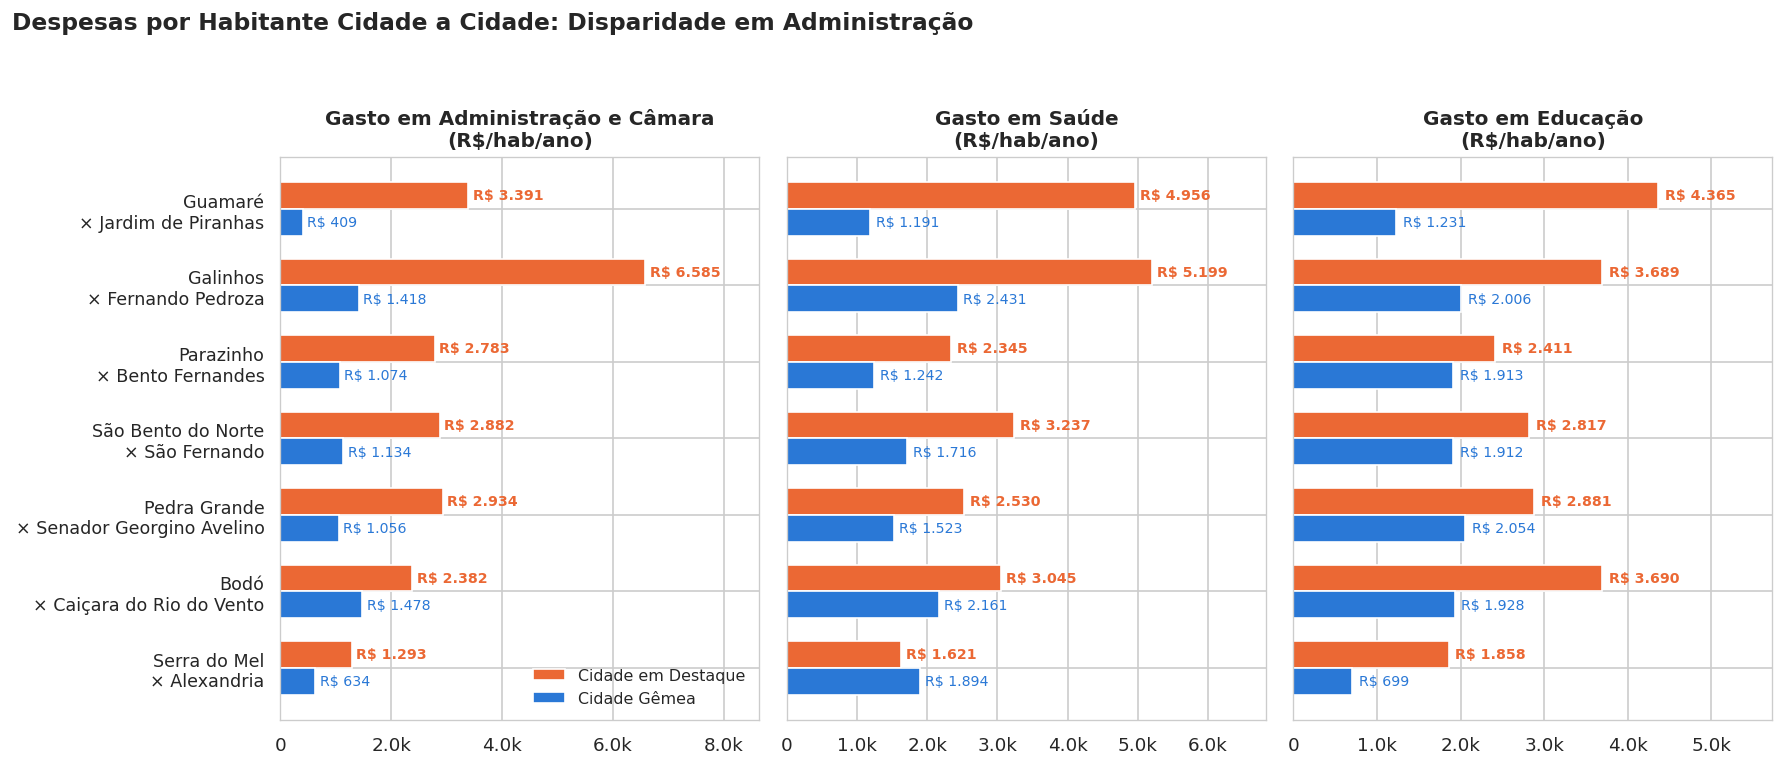

In [9]:
# Gráfico 4: Gastos por Habitante Cidade a Cidade (3 Subplots)
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)

areas_comp = [
    ('Administração e Câmara', ROXO, axes[0]),
    ('Saúde', VERDE, axes[1]),
    ('Educação', AZUL, axes[2])
]

y_pos_base = np.arange(len(PARES))[::-1]
altura = 0.35

for area_nome, cor, ax in areas_comp:
    for idx, (d, g) in enumerate(PARES):
        yi = y_pos_base[idx]
        val_d = area_pc.loc[d, area_nome]
        val_g = area_pc.loc[g, area_nome]

        ax.barh(yi + altura/2, val_d, height=altura, color=LARANJA, edgecolor='white', label='Cidade em Destaque' if idx==0 else '')
        ax.barh(yi - altura/2, val_g, height=altura, color=AZUL, edgecolor='white', label='Cidade Gêmea' if idx==0 else '')

        # Anotações dos valores
        ax.text(val_d + 80, yi + altura/2, f'R$ {val_d:,.0f}'.replace(',', '.'), va='center', fontsize=8.5, fontweight='bold', color=LARANJA)
        ax.text(val_g + 80, yi - altura/2, f'R$ {val_g:,.0f}'.replace(',', '.'), va='center', fontsize=8.5, color=AZUL)

    ax.set_title(f'Gasto em {area_nome}\n(R$/hab/ano)', fontsize=12, fontweight='bold')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1000:.1f}k' if x>=1000 else f'{x:.0f}'))
    ax.set_xlim(0, ax.get_xlim()[1] * 1.25)

axes[0].set_yticks(y_pos_base)
axes[0].set_yticklabels([f'{d}\n× {g}' for d, g in PARES], fontsize=10.5)
axes[0].legend(loc='lower right', frameon=False, fontsize=9.5)

fig.suptitle('Despesas por Habitante Cidade a Cidade: Disparidade em Administração',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


### Gráfico 5: Indicadores Sociais Par a Par (Água, Esgoto, CadÚnico e IDEB)

O painel de 4 gráficos abaixo coloca cada par de cidades frente a frente nos indicadores sociais de entrega real para o cidadão:
* **Água da Rede**: Em **6 dos 7 pares**, a cidade gêmea comum tem maior percentual de domicílios abastecidos com água tratada encanada do que a cidade bilionária em royalties.
* **Pobreza no CadÚnico**: Apesar de arrecadar até 5 vezes mais por morador, as cidades em destaque mantêm proporções de extrema pobreza e vulnerabilidade social idênticas ou superiores às de suas cidades gêmeas.

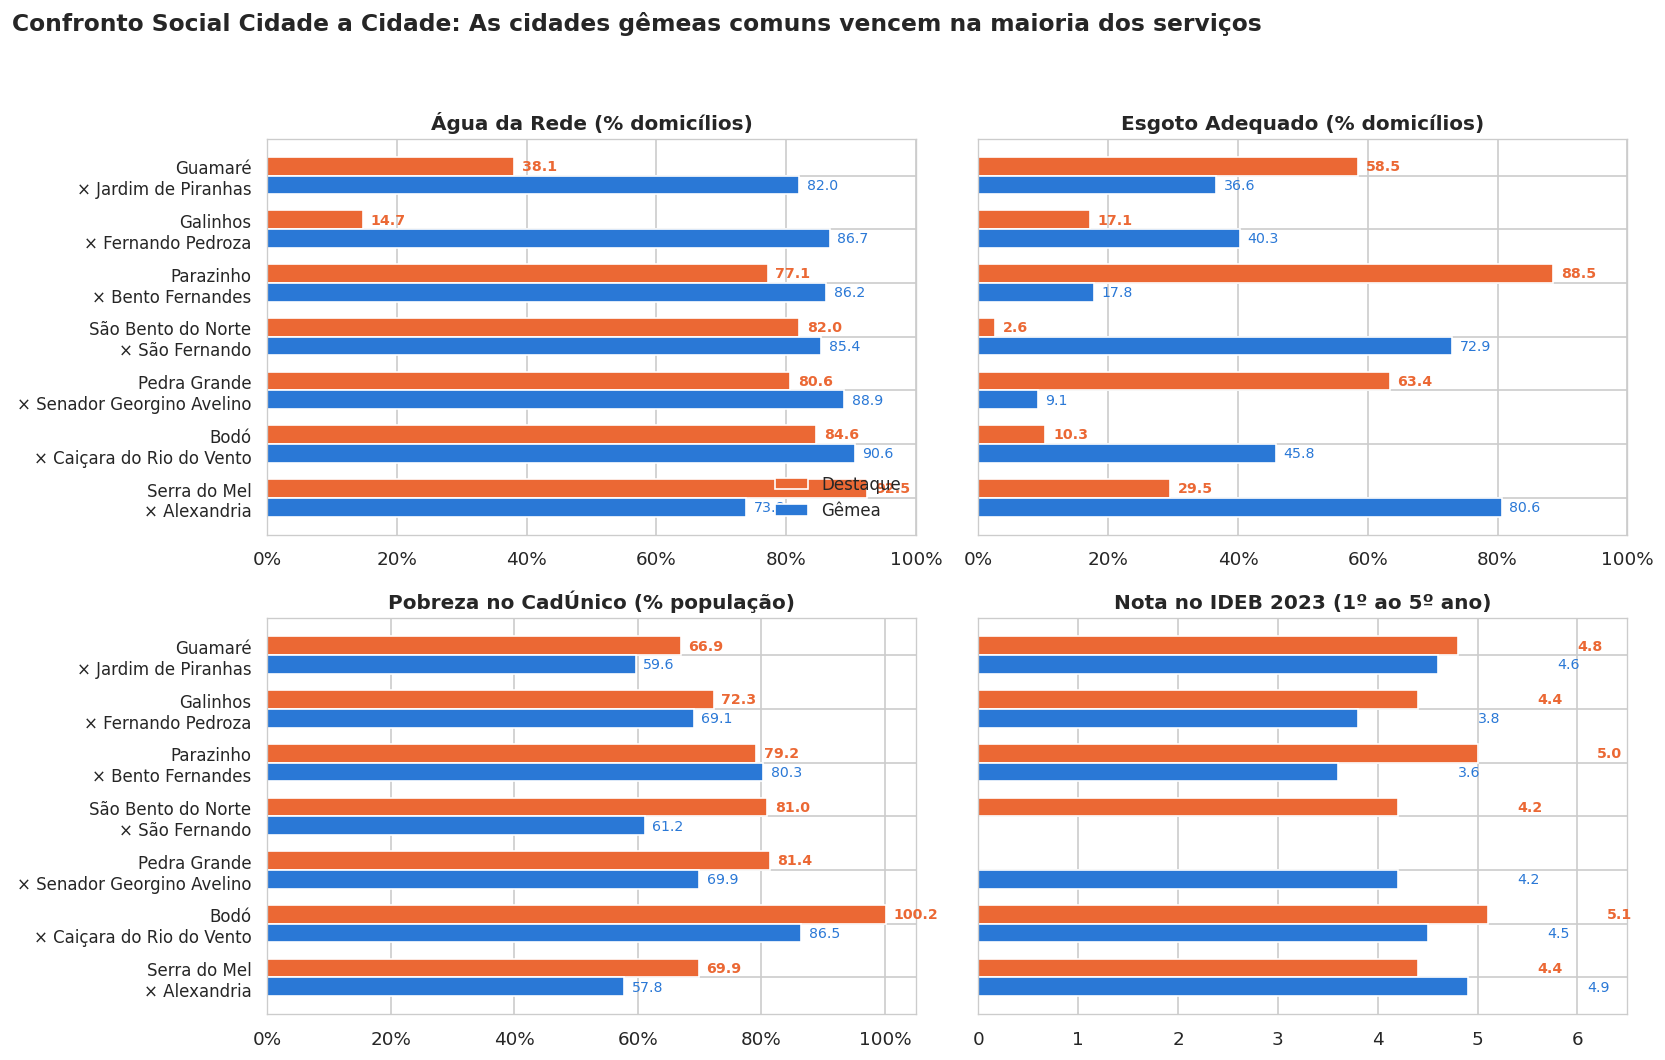

In [10]:
# Gráfico 5: Confronto Par a Par nos 4 Indicadores Sociais Principais
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)

indicadores_painel = [
    ('Água da Rede (% domicílios)', 'agua22', axes[0, 0], '%', 100),
    ('Esgoto Adequado (% domicílios)', 'esg22', axes[0, 1], '%', 100),
    ('Pobreza no CadÚnico (% população)', 'cad_media', axes[1, 0], '%', 105),
    ('Nota no IDEB 2023 (1º ao 5º ano)', 'ai_2023', axes[1, 1], 'pts', 6.5)
]

for tit, col, ax, unidade, lim_x in indicadores_painel:
    for idx, (d, g) in enumerate(PARES):
        yi = y_pos_base[idx]
        vd = ind_i.loc[d, col]
        vg = ind_i.loc[g, col]

        if not pd.isna(vd):
            ax.barh(yi + altura/2, vd, height=altura, color=LARANJA, edgecolor='white', label='Destaque' if idx==0 else '')
            ax.text(vd + 1.2, yi + altura/2, f'{vd:.1f}', va='center', fontsize=8.5, fontweight='bold', color=LARANJA)
        if not pd.isna(vg):
            ax.barh(yi - altura/2, vg, height=altura, color=AZUL, edgecolor='white', label='Gêmea' if idx==0 else '')
            ax.text(vg + 1.2, yi - altura/2, f'{vg:.1f}', va='center', fontsize=8.5, color=AZUL)

    ax.set_title(tit, fontsize=12, fontweight='bold')
    ax.set_xlim(0, lim_x)
    if unidade == '%':
        ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

axes[0, 0].set_yticks(y_pos_base)
axes[0, 0].set_yticklabels([f'{d}\n× {g}' for d, g in PARES], fontsize=10)
axes[1, 0].set_yticks(y_pos_base)
axes[1, 0].set_yticklabels([f'{d}\n× {g}' for d, g in PARES], fontsize=10)
axes[0, 0].legend(loc='lower right', frameon=False, fontsize=10)

fig.suptitle('Confronto Social Cidade a Cidade: As cidades gêmeas comuns vencem na maioria dos serviços',
             x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()


### Gráfico 6: Matriz de Confronto Direto Par a Par (Heatmap com Valores Reais)

A matriz abaixo resume o resultado de cada par em cada um dos 7 indicadores avaliados:
* **Quadrado Verde (+1)**: Cidade em Destaque teve melhor desempenho.
* **Quadrado Vermelho (-1)**: Cidade Gêmea teve melhor desempenho.
* **Quadrado Cinza (0)**: Empate técnico ou ausência de dados.

Os valores numéricos de ambas as cidades estão inscritos dentro de cada quadrado para consulta imediata durante a apresentação.

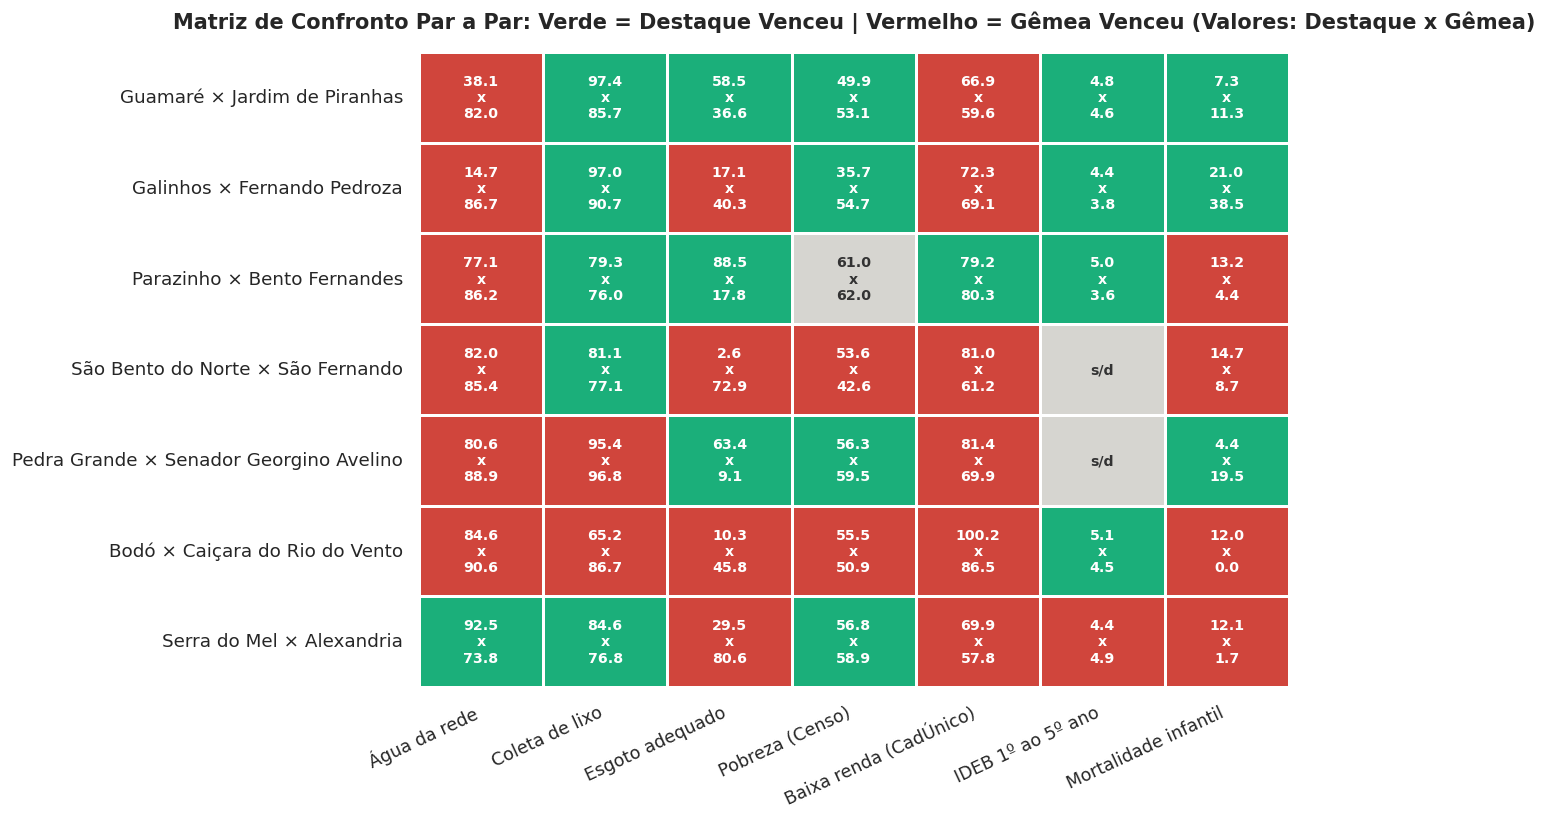

In [11]:
# Gráfico 6: Heatmap de Confronto Direto Par a Par
INDICADORES_HEAT = [
    ('Água da rede', 'agua22', True, 1.0),
    ('Coleta de lixo', 'lixo22', True, 1.0),
    ('Esgoto adequado', 'esg22', True, 2.0),
    ('Pobreza (Censo)', 'pct_ate_meio_sm_censo', False, 1.0),
    ('Baixa renda (CadÚnico)', 'cad_media', False, 1.0),
    ('IDEB 1º ao 5º ano', 'ai_2023', True, 0.1),
    ('Mortalidade infantil', 'mort_2020_2023', False, 2.0)
]

matriz_pontos = np.zeros((len(PARES), len(INDICADORES_HEAT)))
matriz_textos = []

for i, (d, g) in enumerate(PARES):
    linha_txt = []
    for j, (nome_rot, col, maior_melhor, tol) in enumerate(INDICADORES_HEAT):
        vd = ind_i.loc[d, col]
        vg = ind_i.loc[g, col]

        if pd.isna(vd) or pd.isna(vg):
            matriz_pontos[i, j] = 0
            linha_txt.append('s/d')
        else:
            dif = (vd - vg) if maior_melhor else (vg - vd)
            if abs(dif) < tol:
                matriz_pontos[i, j] = 0
            elif dif > 0:
                matriz_pontos[i, j] = 1   # Destaque venceu
            else:
                matriz_pontos[i, j] = -1  # Gêmea venceu

            fmt_d = f'{vd:.1f}' if isinstance(vd, (int, float)) else str(vd)
            fmt_g = f'{vg:.1f}' if isinstance(vg, (int, float)) else str(vg)
            linha_txt.append(f'{fmt_d}\nx\n{fmt_g}')
    matriz_textos.append(linha_txt)

fig, ax = plt.subplots(figsize=(11, 7))
cmap_custom = sns.color_palette(['#d0453c', '#d6d5d0', '#1baf7a'])

sns.heatmap(matriz_pontos, cmap=cmap_custom, cbar=False, ax=ax,
            linewidths=1.5, linecolor='white')

# Inscrição dos valores dentro das células
for i in range(len(PARES)):
    for j in range(len(INDICADORES_HEAT)):
        ax.text(j + 0.5, i + 0.5, matriz_textos[i][j],
                ha='center', va='center', fontsize=8.5, fontweight='bold',
                color='white' if matriz_pontos[i, j] != 0 else '#333333')

ax.set_xticks(np.arange(len(INDICADORES_HEAT)) + 0.5)
ax.set_xticklabels([n[0] for n in INDICADORES_HEAT], fontsize=10.5, rotation=25, ha='right')
ax.set_yticks(np.arange(len(PARES)) + 0.5)
ax.set_yticklabels([f'{d} × {g}' for d, g in PARES], fontsize=11, rotation=0)

ax.set_title('Matriz de Confronto Par a Par: Verde = Destaque Venceu | Vermelho = Gêmea Venceu (Valores: Destaque x Gêmea)',
             pad=14, fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()


### Diagnóstico dos Casos Emblemáticos Cidade a Cidade

Ao analisar os pares individualmente, identificamos três realidades claras:

#### Caso 1: Guamaré × Jardim de Piranhas
* **Receita:** Guamaré arrecada **R\$ 19.877/hab/ano** (chegando a R\$ 26,7 mil no orçamento total do SICONFI), enquanto Jardim de Piranhas arrecada **R\$ 4.064/hab/ano** (uma disparidade de 4,9 vezes). O FPM é idêntico (~R\$ 1.500/hab); os R\$ 12.789/hab a mais vêm exclusivamente do petróleo.
* **Onde vai o dinheiro:** Guamaré gasta **R\$ 3.391/hab apenas em Administração Geral e Câmara Municipal**. Esse gasto administrativo sozinho é quase igual a todo o orçamento anual de Jardim de Piranhas. A taxa de investimento em infraestrutura é de irrisórios **1,7%**.
* **Resultado Social:** Jardim de Piranhas tem **82,0% de domicílios com água encanada**, enquanto Guamaré tem apenas **38,1%**. Jardim de Piranhas tem menor taxa de pobreza no CadÚnico (59,6% vs 66,9%) e notas escolares similares no IDEB (4,6 vs 4,8).

#### Caso 2: Galinhos × Fernando Pedroza
* **Receita:** Galinhos possui apenas 2.104 habitantes e arrecada **R\$ 19.372/hab/ano**, enquanto Fernando Pedroza arrecada R\$ 8.760/hab.
* **Onde vai o dinheiro:** Galinhos gasta **R\$ 6.585/hab em Administração e Câmara** (o maior valor per capita de todo o Rio Grande do Norte). Sua taxa de investimento em obras é de apenas **2,7%**.
* **Resultado Social:** Galinhos tem uma cobertura catastrófica de água tratada encanada pelo Censo 2022 (**apenas 14,7% dos domicílios**), enquanto Fernando Pedroza atende **86,7%** da sua população. Galinhos também tem maior proporção de pobreza no CadÚnico (72,3% vs 69,1%).

#### Caso 3: Parazinho × Bento Fernandes
* **População:** Parazinho tem 4.801 habitantes e Bento Fernandes tem 4.807 habitantes (diferença demográfica de apenas 6 pessoas).
* **FPM idêntico:** Ambas recebem exatamente o mesmo FPM: **R\$ 2.854/hab vs R\$ 2.851/hab**.
* **A diferença dos royalties eólicos:** Parazinho recebe R\$ 4.846/hab de repasses estaduais/eólicos, contra apenas R\$ 575/hab de Bento Fernandes.
* **Resultado Social:** Parazinho converteu parte dos recursos em uma rede escolar melhor (IDEB de 5,0 vs 3,6), mas Bento Fernandes mantém maior cobertura de água encanada (86,2% vs 77,1%) e taxas equivalentes de pobreza.

#### Caso 4: Serra do Mel × Alexandria
* Serra do Mel direcionou **74% do seu gasto excedente para Educação** e apresentou uma taxa de investimento de **10,8%**, comprovando que quando há intencionalidade de gestão e planejamento orçamentário, a receita de royalties pode ser convertida em infraestrutura.



## 6. Visão Macroscópica dos 167 Municípios e Robustez Estatística

Expandindo a análise para todos os **167 municípios do Rio Grande do Norte**, testamos se a ausência de relação observada nos 7 pares se repete em nível estadual através de diagramas de dispersão logarítmica e correlações parciais controladas pelo tamanho populacional.


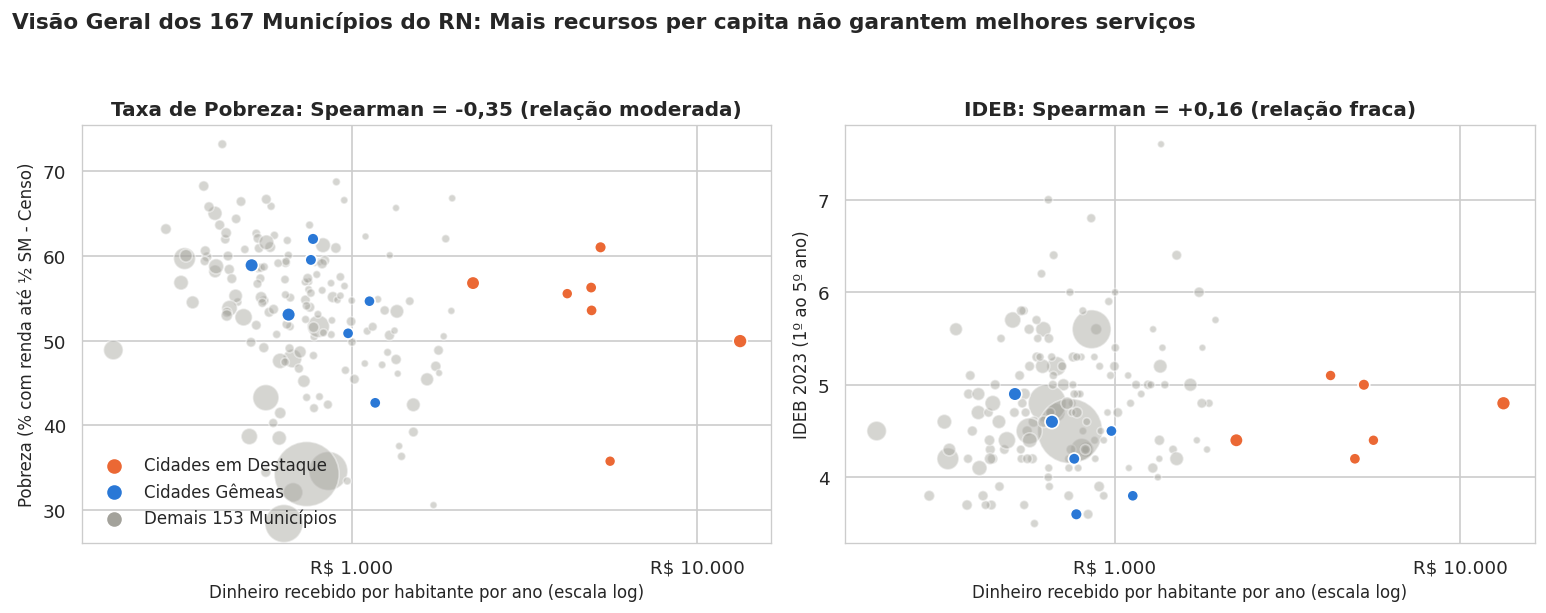

In [12]:
# Gráfico 7: Dispersão nos 167 Municípios (Receita vs Pobreza e IDEB)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for ax, col, rot, tit in [(axes[0], 'pct_ate_meio_sm_censo', 'Pobreza (% com renda até ½ SM - Censo)', 'Taxa de Pobreza'),
                         (axes[1], 'ai_2023', 'IDEB 2023 (1º ao 5º ano)', 'IDEB')]:
    dd = ind.dropna(subset=[col, 'total_pc_ano'])
    outros = dd[~dd['municipio'].isin(CIDADES)]

    ax.scatter(outros['total_pc_ano'], outros[col], s=outros['populacao'] / 500 + 14,
               color=CINZA, alpha=0.45, edgecolor='white')

    for lista, cor in [(DESTAQUES, LARANJA), (GEMEAS, AZUL)]:
        sub = dd[dd['municipio'].isin(lista)]
        ax.scatter(sub['total_pc_ano'], sub[col], s=sub['populacao'] / 500 + 40,
                   color=cor, edgecolor='white', zorder=3)

    rho, p_val = stats.spearmanr(dd['total_pc_ano'], dd[col])
    ax.set_xscale('log')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'R$ {v:,.0f}'.replace(',', '.')))
    ax.set_xlabel('Dinheiro recebido por habitante por ano (escala log)', fontsize=10)
    ax.set_ylabel(rot, fontsize=10)
    ax.set_title(f'{tit}: Spearman = {rho:+.2f}'.replace('.', ',') + (' (relação moderada)' if abs(rho)>0.3 else ' (relação fraca)'),
                 fontsize=12, fontweight='bold')

axes[0].scatter([], [], color=LARANJA, s=60, label='Cidades em Destaque')
axes[0].scatter([], [], color=AZUL, s=60, label='Cidades Gêmeas')
axes[0].scatter([], [], color=CINZA, s=60, label='Demais 153 Municípios')
axes[0].legend(frameon=False, loc='lower left', fontsize=10)

fig.suptitle('Visão Geral dos 167 Municípios do RN: Mais recursos per capita não garantem melhores serviços',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()


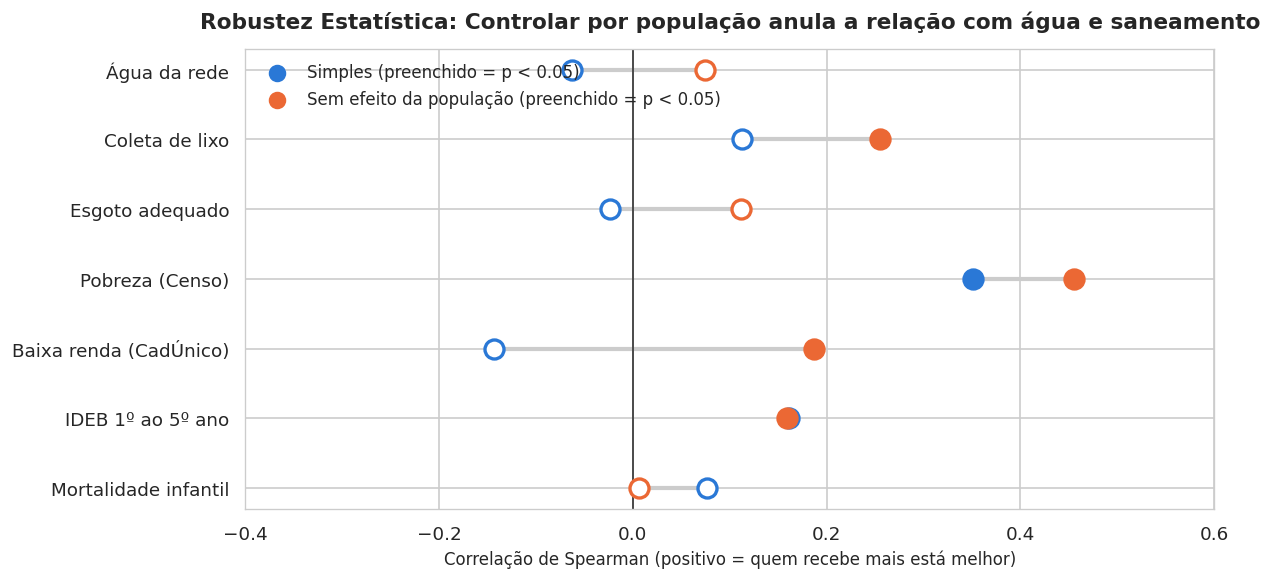

In [13]:
# Gráfico 8: Correlações de Spearman Simples vs Parciais (Controlando População)
def correlacao_parcial(dados, x, y, controle):
    df_val = dados[[x, y, controle]].dropna()
    r = df_val.rank()
    res_x = r[x] - np.poly1d(np.polyfit(r[controle], r[x], 1))(r[controle])
    res_y = r[y] - np.poly1d(np.polyfit(r[controle], r[y], 1))(r[controle])
    return stats.pearsonr(res_x, res_y)

linhas_corr = []
for nome_rotulo, col, maior_melhor, _ in INDICADORES_HEAT:
    sub = ind.dropna(subset=['total_pc_ano', col, 'populacao'])
    r_simp, p_simp = stats.spearmanr(sub['total_pc_ano'], sub[col])
    r_parc, p_parc = correlacao_parcial(sub, 'total_pc_ano', col, 'populacao')
    sinal = 1 if maior_melhor else -1
    linhas_corr.append({
        'Indicador': nome_rotulo,
        'Simples': r_simp * sinal,
        'p simples': p_simp,
        'Sem efeito da população': r_parc * sinal,
        'p parcial': p_parc
    })

df_corr = pd.DataFrame(linhas_corr)

fig, ax = plt.subplots(figsize=(10.5, 5))
y_pos = np.arange(len(df_corr))[::-1]

for yi, (_, r) in zip(y_pos, df_corr.iterrows()):
    ax.plot([r['Simples'], r['Sem efeito da população']], [yi, yi], color='#cccccc', lw=2.5, zorder=1)
    ax.scatter(r['Simples'], yi, s=130, facecolor=(AZUL if r['p simples'] < 0.05 else 'white'),
               edgecolor=AZUL, linewidth=2, zorder=3)
    ax.scatter(r['Sem efeito da população'], yi, s=130, facecolor=(LARANJA if r['p parcial'] < 0.05 else 'white'),
               edgecolor=LARANJA, linewidth=2, zorder=3)

ax.axvline(0, color='#333333', lw=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_corr['Indicador'], fontsize=11)
ax.set_xlim(-0.4, 0.6)
ax.set_xlabel('Correlação de Spearman (positivo = quem recebe mais está melhor)', fontsize=10)
ax.set_title('Robustez Estatística: Controlar por população anula a relação com água e saneamento', pad=12, fontsize=13)

ax.scatter([], [], s=90, facecolor=AZUL, edgecolor=AZUL, label='Simples (preenchido = p < 0.05)')
ax.scatter([], [], s=90, facecolor=LARANJA, edgecolor=LARANJA, label='Sem efeito da população (preenchido = p < 0.05)')
ax.legend(frameon=False, loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()


## 7. Conclusões Executivas e Resposta Direta à Banca

Com base nos dados analisados ao longo do projeto, respondemos com rigor às orientações da banca e à pergunta norteadora:

### 1. Resposta Direta à Pergunta Norteadora:
> *"Existe dependência do fundo de participação para ofertar serviços de qualidade para a população?"*

* **Dependência do FPM para a existência do município: SIM.**
  Para a esmagadora maioria dos municípios do RN (representados pelas cidades gêmeas), o FPM responde por **metade (48% a 51%) de toda a receita corrente**. Sem o fundo de participação, as prefeituras não conseguem sequer pagar a folha de pessoal ou manter postos de saúde abertos.
* **Dependência do FPM nas cidades ricas: NÃO (há substituição por royalties/ICMS).**
  As cidades fora da curva mantêm uma dependência quase idêntica de transferências externas (89%), mas **trocam a dependência do FPM pela dependência do ICMS e de royalties estaduais** (que chegam a representar de 30% a 64% da sua receita).
* **Conversão de recursos em serviços de qualidade: NÃO.**
  O comparativo cidade a cidade comprova que receber até 4,9 vezes mais receita por habitante **não se traduz em melhores serviços de água encanada, esgotamento sanitário ou índices educacionais superiores**. As cidades gêmeas comuns venceram o confronto social em 25 indicadores contra 21 das destacadas, apresentando melhor rede de água tratada em 6 dos 7 pares.

---

### 2. Para onde vai o dinheiro?
* **Captura burocrática:** A cada R\$ 100 adicionais por habitante gastos pelas cidades ricas, **R\$ 40 vão diretamente para Administração Geral e Câmaras Municipais**, enquanto menos de R\$ 0,50 vão para saneamento básico ou urbanismo. Em casos extremos como Galinhos, o gasto com gabinetes chega a R\$ 6.585 por habitante ao ano.

* **Baixa taxa de investimento:** Mais de 90% dos orçamentos dessas prefeituras são consumidos por despesas correntes de manutenção da máquina e contratos de custeio. A taxa média de investimento em infraestrutura permanente é irrisória (1,7% em Guamaré e 2,7% em Galinhos).
